# Overdamped Langevin: bias, correction and adaptation
For $\pi(x)\propto e^{-U(x)}$, ULA proposes $x'=x-h\nabla U(x)+\sqrt{2h}z$; MALA adds the reverse/forward proposal correction. We compare independent chains at equal iteration budgets, then inspect difficult geometries. [R01](../docs/references.md#r01), [R02](../docs/references.md#r02), [R03](../docs/references.md#r03).

The [paper interpretation](../docs/algorithms/paper-interpretation.md) distinguishes the paper's quartic Rosenbrock from the separate Gaussian banana below. Outputs are finite-run demonstrations, not convergence certificates.

In [1]:
import os, json, time, platform
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lafa import samplers
from lafa.problems import Gaussian, GaussianMixture2D, Banana2D

torch.set_num_threads(1)
device = torch.device(os.environ.get('LAFA_DEVICE', 'cpu'))
if device.type == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('LAFA_DEVICE=cuda requested, but CUDA is unavailable')
dtype, seed = torch.float64, 2026
quick = os.environ.get('LAFA_QUICK', '1') == '1'
torch.manual_seed(seed)
def gen(offset=0):
    return torch.Generator(device=device).manual_seed(seed + offset)
def tensor(x): return torch.as_tensor(x, device=device, dtype=dtype)
def cpu(x): return x.detach().cpu().numpy()
def sync():
    if device.type == 'cuda': torch.cuda.synchronize(device)
def table(rows):
    keys = list(dict.fromkeys(k for row in rows for k in row))
    display(Markdown('| ' + ' | '.join(keys) + ' |\n|' + '|'.join(['---']*len(keys)) + '|\n' +
        '\n'.join('| ' + ' | '.join(f'{r[k]:.4g}' if isinstance(r.get(k),float) else str(r.get(k, '—')) for k in keys) + ' |' for r in rows)))
def contour(ax, target, bounds=(-5,5,-5,5)):
    a=torch.linspace(bounds[0],bounds[1],100,device=device,dtype=dtype)
    b=torch.linspace(bounds[2],bounds[3],100,device=device,dtype=dtype)
    xx,yy=torch.meshgrid(a,b,indexing='xy')
    with torch.no_grad(): u=target(torch.stack((xx,yy),-1))
    ax.contour(cpu(xx),cpu(yy),cpu(u-u.min()),levels=[.5,1,2,4,8,16],colors='0.7',linewidths=.6)
    ax.set(xlim=bounds[:2],ylim=bounds[2:]); ax.set_aspect('equal')
def covariance(x):
    z=x-x.mean(0); return z.T@z/(len(x)-1)
def collect(method, steps, burn=0, thin=1):
    samples=[]; trace=[]; hs=[]; accepted=[]
    for i in range(steps):
        r=method.step(); trace.append(r.position.reshape(-1,r.position.shape[-1])[0].clone())
        hs.append(float(torch.as_tensor(r.stats.get('step_size',getattr(method,'step_size',float('nan')))).double().mean()))
        if getattr(r,'accepted',None) is not None: accepted.append(r.accepted.double().mean())
        if i>=burn and (i-burn)%thin==0: samples.append(r.position.reshape(-1,r.position.shape[-1]))
    return torch.cat(samples),torch.stack(trace),hs,float(torch.stack(accepted).mean()) if accepted else float('nan')
root=Path.cwd() if (Path.cwd()/'docs').exists() else Path.cwd().parent
assets=root/'docs'/'assets'; assets.mkdir(parents=True,exist_ok=True)
print(json.dumps(dict(device=str(device),dtype=str(dtype),seed=seed,quick=quick,torch=torch.__version__,python=platform.python_version(),hardware=torch.cuda.get_device_name(device) if device.type=='cuda' else platform.processor() or platform.machine())))


{"device": "cpu", "dtype": "torch.float64", "seed": 2026, "quick": true, "torch": "2.6.0+cpu", "python": "3.12.14", "hardware": "x86_64"}


In [2]:
from lafa.specialized import AnchoredLangevin
steps=900 if quick else 3000; burn=300 if quick else 1000
chains=96; initial=torch.zeros((chains,2),device=device,dtype=dtype)
target=Gaussian([0,0],[[1,.65],[.65,1]],device=device,dtype=dtype)
methods={
 'ULA':samplers.ULA(target,initial,.12,generator=gen(1)),
 'MALA':samplers.MALA(target,initial,.12,generator=gen(2)),
 'LipULA continuous':samplers.LipULA(target,initial,.02,max_step_size=.45,generator=gen(3)),
 'LipMALA continuous':samplers.LipMALA(target,initial,.02,max_step_size=.45,generator=gen(4)),
 'LipMALA frozen':samplers.LipMALA(target,initial,.02,max_step_size=.45,adapt_steps=burn,generator=gen(5)),
 # Exact reference U0=U+0.2 changes the physical clock, not a quadratic force.
 'Anchored':AnchoredLangevin(target,lambda x:target(x)+.2,initial,.08,generator=gen(6))}
results={}; rows=[]
for name,method in methods.items():
    sync(); start=time.perf_counter(); s,tr,h,acc=collect(method,steps,burn,3); sync()
    results[name]=(s,tr,h)
    rows.append(dict(method=name,seconds=time.perf_counter()-start,mean_error=float(s.mean(0).norm()),covariance_error=float((covariance(s)-target.covariance).norm()),acceptance=acc,production_mean_h=sum(h[burn:])/len(h[burn:])))
table(rows)

| method | seconds | mean_error | covariance_error | acceptance | production_mean_h |
|---|---|---|---|---|---|
| ULA | 0.2434 | 0.02459 | 0.07856 | nan | 0.12 |
| MALA | 0.3328 | 0.0258 | 0.02923 | 0.955 | 0.12 |
| LipULA continuous | 0.4279 | 0.001769 | 0.4165 | nan | 0.3543 |
| LipMALA continuous | 0.479 | 0.005623 | 0.02432 | 0.7514 | 0.3773 |
| LipMALA frozen | 0.4983 | 0.01122 | 0.02824 | 0.7584 | 0.3697 |
| Anchored | 0.4265 | 0.03931 | 0.04069 | nan | 0.08 |

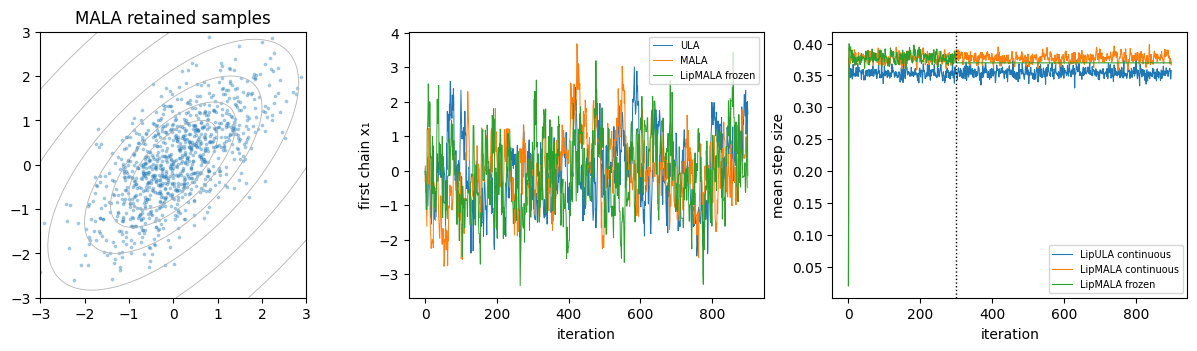

In [3]:
fig,ax=plt.subplots(1,3,figsize=(12,3.4),layout='constrained')
contour(ax[0],target,(-3,3,-3,3)); s=results['MALA'][0]
ax[0].scatter(*cpu(s[::20]).T,s=3,alpha=.3); ax[0].set_title('MALA retained samples')
for name in ['ULA','MALA','LipMALA frozen']:
    ax[1].plot(cpu(results[name][1][:,0]),lw=.7,label=name)
for name in ['LipULA continuous','LipMALA continuous','LipMALA frozen']:
    ax[2].plot(results[name][2],lw=.8,label=name)
ax[1].set(xlabel='iteration',ylabel='first chain x₁'); ax[1].legend(fontsize=7)
ax[2].axvline(burn,color='k',ls=':',lw=1); ax[2].set(xlabel='iteration',ylabel='mean step size'); ax[2].legend(fontsize=7)
fig.savefig(assets/'overdamped.png',dpi=120); plt.show()

Continuous history adaptation changes the transition kernel. Its acceptance rate does **not** establish exact stationarity. The frozen run adapts during warm-up, discards it, and then uses fixed per-chain production steps. Anchored Euler is unadjusted; physical-iteration samples and equal operational-clock samples have different targets. Here $U_0=U+0.2$ is an explicit exact-reference sanity case.

In [4]:
sweep=[]
for h in [.025,.08,.18]:
    for cls in [samplers.ULA,samplers.MALA]:
        s,_,_,a=collect(cls(target,initial,h,generator=gen(20)),steps,burn,3)
        # Gaussian ULA discrete covariance solves C_h=(I-hP)C_h(I-hP)+2hI.
        P=torch.linalg.inv(target.covariance)
        exact_ula=torch.linalg.inv(P-h/2*(P@P))
        sweep.append(dict(method=cls.__name__,h=h,covariance_error=float((covariance(s)-target.covariance).norm()),analytic_ULA_bias=float((exact_ula-target.covariance).norm()) if cls is samplers.ULA else 0.,acceptance=a))
table(sweep)

| method | h | covariance_error | analytic_ULA_bias | acceptance |
|---|---|---|---|---|
| ULA | 0.025 | 0.06558 | 0.01807 | nan |
| MALA | 0.025 | 0.04095 | 0 | 0.996 |
| ULA | 0.08 | 0.05209 | 0.06099 | nan |
| MALA | 0.08 | 0.02333 | 0 | 0.9766 |
| ULA | 0.18 | 0.1325 | 0.1541 | nan |
| MALA | 0.18 | 0.01665 | 0 | 0.9173 |

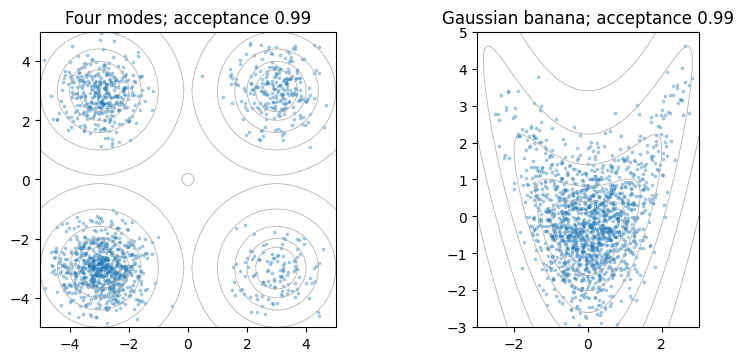

Iterations: 900 burn-in: 300 chains: 96 retention stride: 3


In [5]:
fig,axes=plt.subplots(1,2,figsize=(8,3.5),layout='constrained')
for j,(problem,h,bounds) in enumerate([(GaussianMixture2D(device=device,dtype=dtype),.06,(-5,5,-5,5)),(Banana2D(.6,device=device,dtype=dtype),.035,(-3,3,-3,5))]):
    s,_,_,a=collect(samplers.MALA(problem,initial,h,generator=gen(40+j)),steps,burn,5)
    contour(axes[j],problem,bounds); axes[j].scatter(*cpu(s[::8]).T,s=3,alpha=.3)
    axes[j].set_title(('Four modes' if j==0 else 'Gaussian banana')+f'; acceptance {a:.2f}')
plt.show()
print('Iterations:',steps,'burn-in:',burn,'chains:',chains,'retention stride:',3)

Check mode occupancy, traces and moment error together. A narrow trace or high acceptance can coexist with missed modes; the pooled chains here start at the same point and are not proof of global mixing.